# PBL 4: Combining Models (Boosting and Bayesian Model Averaging)

**Project:** Explainable Machine Learning for Early Prediction of Diabetes Risk Using Clinical Data
**Team 3:** Jai (RA2411026010131), Aggam (RA2411026010139), Alphin (RA2411026010177)
**Topic (Unit 5, Combining Models):** Boosting (AdaBoost) and Bayesian Model Averaging

PBL 1 trained **single models** (logistic regression, one decision tree, one random forest). Unit 5 asks a different question: what happens when we **combine** many models?

- **Boosting** trains weak models **one after another**. Each new model concentrates on the patients the previous ones got wrong, and the final prediction is a weighted vote.
- **Bayesian model averaging (BMA)** keeps many candidate models and weights each one by **how well the data supports it**, instead of picking one winner.

We use the **Kaggle Diabetes Prediction dataset** from PBL 1 (96,146 patients after removing duplicates). Its rounded HbA1c and glucose values (18 distinct values each) ruled it out for the Gaussian models of PBL 2 and 3, but **trees split on thresholds**, so rounded values are no problem here.

| # | Part | Section |
|---|---|---|
| 1 | Theory: committees, AdaBoost, exponential error, Bayesian model averaging | A |
| 2 | Data and preprocessing | B |
| 3 | Boosting: library model, hand-written AdaBoost check, behaviour, comparison, robustness | C |
| 4 | Bayesian model averaging: posterior over 256 models, small-data experiment, BMA vs ensembles | D |
| 5 | Realistic screening without blood tests | E |
| 6 | Conclusion and limitations | F |

## Setup
Import libraries, fix one random seed, and create the figure folder. Everything uses scikit-learn; Bayesian model averaging is a few lines of NumPy on top of logistic regression.

In [1]:
import os
import time
import itertools
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.special import expit
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import AdaBoostClassifier, RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.calibration import calibration_curve
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import (roc_auc_score, average_precision_score, log_loss, brier_score_loss,
                             recall_score, precision_score, f1_score)

RANDOM_STATE = 42  # used everywhere so results are reproducible
warnings.filterwarnings("ignore", category=ConvergenceWarning)   # tiny logistic fits in D.3
os.makedirs("figures/pbl4", exist_ok=True)
sns.set_theme(style="whitegrid")

# Section A: The Idea

## A.1 Combining models (committees)
A **committee** combines the predictions of several models. Averaging $M$ models reduces the error when their mistakes are not all the same. Unit 5 covers three ways to combine:

| Method | How models are trained | How they are combined |
|---|---|---|
| **Bagging** (random forest) | in **parallel**, each on a bootstrap resample of the data | equal vote |
| **Boosting** (AdaBoost) | **one after another**, each focusing on the previous mistakes | weighted vote, better models get more say |
| **Bayesian model averaging** | each candidate model fitted on all the data | weighted by the **posterior probability** of the model |

## A.2 AdaBoost
Labels are coded $t_n \in \{-1, +1\}$ and each weak classifier gives $y_m(x) \in \{-1, +1\}$. Our weak classifier is a **decision stump**: a CART tree with a single split (one feature, one threshold).

1. Start with equal weights $w_n^{(1)} = 1/N$.
2. For $m = 1, \dots, M$:
   - Fit $y_m(x)$ to the data using the weights $w^{(m)}$.
   - Weighted error: $\displaystyle \epsilon_m = \frac{\sum_n w_n^{(m)}\, I(y_m(x_n) \ne t_n)}{\sum_n w_n^{(m)}}$
   - Classifier weight: $\displaystyle \alpha_m = \ln\frac{1-\epsilon_m}{\epsilon_m}$ (a smaller error gives a bigger say)
   - Update the data weights: $w_n^{(m+1)} = w_n^{(m)} \exp\big(\alpha_m\, I(y_m(x_n) \ne t_n)\big)$, so **misclassified patients get heavier**.
3. Final classifier: $\displaystyle Y_M(x) = \operatorname{sign}\Big(\sum_{m=1}^{M} \alpha_m\, y_m(x)\Big)$

The textbook writes the classifier weight as $\tfrac{1}{2}\ln\frac{1-\epsilon_m}{\epsilon_m}$. scikit-learn's AdaBoost (algorithm "SAMME") drops the $\tfrac{1}{2}$. That doubles every $\alpha_m$, which does not change the sign of the vote, so the predictions are identical. We use the scikit-learn form so that our hand-written version can be checked number for number.

## A.3 Boosting minimises an exponential error
AdaBoost can be derived as greedily minimising the **exponential error**
$$E = \sum_{n=1}^{N} \exp\big(-t_n f_m(x_n)\big), \qquad f_m(x) = \tfrac{1}{2}\sum_{l=1}^{m} \alpha_l\, y_l(x)$$
A misclassified point has $t_n f_m(x_n) < 0$, so its term grows exponentially: this is why boosting chases hard points, and also why it is **sensitive to outliers and wrong labels**. Two useful consequences:

- **Training error bound:** the average exponential error equals $\prod_m 2\sqrt{\epsilon_m(1-\epsilon_m)}$, and it is always above the training error rate. Each round with $\epsilon_m < 0.5$ shrinks it.
- **Probabilities:** the function that minimises the expected exponential error is $f(x) = \tfrac{1}{2}\ln\frac{p(t=1 \mid x)}{p(t=-1 \mid x)}$, **half the log-odds**. So the vote can be turned back into a probability with $p(t = 1 \mid x) = \sigma\big(2 f(x)\big) = \sigma\big(\sum_m \alpha_m y_m(x)\big)$ in the scikit-learn scaling.

Other error functions from the same chapter: **cross-entropy** $\ln(1 + e^{-ty})$ (logistic regression, gradient boosting), **hinge** $\max(0, 1 - ty)$ (support vector machines) and **misclassification** $I(ty < 0)$ (gives no gradient).

## A.4 Bayesian model averaging
Suppose we have candidate models $M_1, \dots, M_K$ (here: logistic regressions that use different sets of features). Instead of choosing one, BMA averages their predictions, weighted by the posterior probability of each model:
$$p(t \mid x, D) = \sum_{k=1}^{K} p(t \mid x, M_k, D)\; p(M_k \mid D), \qquad p(M_k \mid D) = \frac{p(D \mid M_k)\, p(M_k)}{\sum_j p(D \mid M_j)\, p(M_j)}$$
The **evidence** $p(D \mid M_k)$ is hard to compute exactly. We use the **Bayesian Information Criterion** from PBL 2, which approximates it: $\ln p(D \mid M_k) \approx -\tfrac{1}{2}\mathrm{BIC}_k$, with $\mathrm{BIC}_k = -2 \ln L_k + p_k \ln N$. With equal prior probability for every model:
$$p(M_k \mid D) \approx \frac{\exp(-\tfrac{1}{2}\mathrm{BIC}_k)}{\sum_j \exp(-\tfrac{1}{2}\mathrm{BIC}_j)}$$
The **posterior inclusion probability** of a feature is the total posterior weight of the models that contain it: a direct, explainable measure of how much the data supports that feature.

**BMA is not an ensemble.** BMA assumes that **one** of the models is the true one and expresses uncertainty about which. As the data grows, the posterior concentrates on a single model and BMA turns into model selection. An ensemble such as boosting instead **builds a new, richer model** out of the combination; it does not assume any single member is correct.

# Section B: Data

## B.1 Load and clean
Same steps as the PBL 1 Kaggle notebook: drop exact duplicate rows, and treat BMI = 27.32 as missing (it is a filled-in placeholder value, not a measurement).

In [2]:
df = pd.read_csv("data/kaggle_dataset/diabetes_prediction_dataset.csv")
print("Raw shape:", df.shape)
df = df.drop_duplicates().reset_index(drop=True)
print("After removing duplicates:", df.shape)
df.loc[df["bmi"] == 27.32, "bmi"] = np.nan
print("BMI placeholder 27.32 set to missing: %d rows (%.1f%%)" % (df["bmi"].isna().sum(), df["bmi"].isna().mean() * 100))
print("Diabetic share: %.3f" % df["diabetes"].mean())
print("Distinct values: HbA1c %d, glucose %d" % (df["HbA1c_level"].nunique(), df["blood_glucose_level"].nunique()))

Raw shape: (100000, 9)
After removing duplicates: (96146, 9)
BMI placeholder 27.32 set to missing: 21666 rows (22.5%)
Diabetic share: 0.088
Distinct values: HbA1c 18, glucose 18


## B.2 Split, impute, encode
- **Split:** 80 / 20, stratified on the label, `random_state = 42`: the same split as PBL 1, so the results are comparable.
- **Missing BMI:** filled with the **training** median (no information from the test set).
- **Categories:** `gender` and `smoking_history` are one-hot encoded. `"No Info"` stays as its own smoking category.
- **No scaling for trees:** a split threshold does not care about units. Only the logistic regressions in Section D are standardised.

In [3]:
train_df, test_df = train_test_split(df, test_size=0.2, stratify=df["diabetes"], random_state=RANDOM_STATE)
bmi_median = train_df["bmi"].median()

def prepare(d):
    X = d.drop(columns="diabetes").copy()
    X["bmi"] = X["bmi"].fillna(bmi_median)
    return pd.get_dummies(X, columns=["gender", "smoking_history"], dtype=float)

X_train = prepare(train_df)
X_test = prepare(test_df).reindex(columns=X_train.columns, fill_value=0.0)
y_train = train_df["diabetes"].to_numpy()
y_test = test_df["diabetes"].to_numpy()
Xtr, Xte = X_train.to_numpy(), X_test.to_numpy()     # plain arrays for the hand-written code
features = list(X_train.columns)

print("Train:", X_train.shape, " Test:", X_test.shape)
print("Diabetic share  train %.4f  test %.4f" % (y_train.mean(), y_test.mean()))
print("Training median BMI used for filling: %.2f" % bmi_median)
print(features)

Train: (76916, 15)  Test: (19230, 15)
Diabetic share  train 0.0882  test 0.0882
Training median BMI used for filling: 26.50
['age', 'hypertension', 'heart_disease', 'bmi', 'HbA1c_level', 'blood_glucose_level', 'gender_Female', 'gender_Male', 'gender_Other', 'smoking_history_No Info', 'smoking_history_current', 'smoking_history_ever', 'smoking_history_former', 'smoking_history_never', 'smoking_history_not current']


**Observation:** After removing 3,854 duplicate rows there are **96,146 patients**, split into **76,916 for training and 19,230 for testing**, both with the same diabetic share (**8.82%**). The BMI placeholder 27.32 affected 21,666 patients (22.5%); they get the training median, 26.50. One-hot encoding turns the 8 inputs into **15 columns**. HbA1c and glucose still have only 18 distinct values each, which is fine for trees: a split only needs a threshold between two values.

# Section C: Boosting

## C.1 Weak and single learners
Two baselines first: a **decision stump** (one split, the weak learner AdaBoost will combine) and a **single CART tree** of depth 6. A helper collects the same metrics for every model:
- **ROC-AUC:** how well the scores rank diabetic above non-diabetic patients (1 = perfect, 0.5 = random).
- **Average precision (AP):** area under the precision-recall curve. More informative than ROC-AUC when only 8.8% of patients are positive.
- **Log loss:** how good the predicted **probabilities** are (lower is better).
- **Recall, precision, F1** at the default threshold 0.5.

In [4]:
results = {}
def evaluate(name, p):
    pred = (p >= 0.5).astype(int)
    results[name] = {"ROC-AUC": roc_auc_score(y_test, p),
                     "Avg precision": average_precision_score(y_test, p),
                     "Log loss": log_loss(y_test, np.clip(p, 1e-12, 1 - 1e-12)),
                     "Recall": recall_score(y_test, pred),
                     "Precision": precision_score(y_test, pred, zero_division=0),
                     "F1": f1_score(y_test, pred)}
    return pd.Series(results[name]).round(4)

stump = DecisionTreeClassifier(max_depth=1, random_state=RANDOM_STATE).fit(Xtr, y_train)
print("Stump splits on %s <= %.2f" % (features[stump.tree_.feature[0]], stump.tree_.threshold[0]))
print(evaluate("Single stump", stump.predict_proba(Xte)[:, 1]).to_dict())

tree = DecisionTreeClassifier(max_depth=6, random_state=RANDOM_STATE).fit(Xtr, y_train)
print(evaluate("CART tree (depth 6)", tree.predict_proba(Xte)[:, 1]).to_dict())

Stump splits on HbA1c_level <= 6.70
{'ROC-AUC': 0.7373, 'Avg precision': 0.521, 'Log loss': 0.1856, 'Recall': 0.4746, 'Precision': 1.0, 'F1': 0.6437}


{'ROC-AUC': 0.9618, 'Avg precision': 0.8248, 'Log loss': 0.0933, 'Recall': 0.6781, 'Precision': 1.0, 'F1': 0.8082}


**Observation:** - **One stump is already informative.** It splits on **HbA1c <= 6.70**. Everyone above that threshold is diabetic in this data (precision **1.000**), but it catches only **47.5%** of diabetic patients, so its ROC-AUC is only **0.737**. This is the "weak learner" boosting starts from.
- **One CART tree of depth 6** reaches ROC-AUC **0.962** and finds **67.8%** of diabetic patients, still with no false alarms.

## C.2 AdaBoost with 500 stumps (library)
`AdaBoostClassifier` with a depth-1 tree as the weak learner and 500 rounds. The table shows the first eight stumps: which feature each one splits on, its weighted error $\epsilon_m$ and its say $\alpha_m$.

In [5]:
N_ROUNDS = 500
t0 = time.time()
ada = AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=1), n_estimators=N_ROUNDS,
                         random_state=RANDOM_STATE).fit(Xtr, y_train)
print("Fitted %d stumps in %.1f s" % (len(ada.estimators_), time.time() - t0))

first = pd.DataFrame({"feature": [features[e.tree_.feature[0]] for e in ada.estimators_[:8]],
                      "threshold": [e.tree_.threshold[0] for e in ada.estimators_[:8]],
                      "weighted error eps_m": ada.estimator_errors_[:8],
                      "alpha_m": ada.estimator_weights_[:8]}, index=range(1, 9))
first.index.name = "round m"
first.round(4)

Fitted 500 stumps in 24.6 s


,feature,threshold,weighted error eps_m,alpha_m
round m,,,,
1,HbA1c_level,6.70,0.0481,2.9842
2,HbA1c_level,5.35,0.2802,0.9435
3,blood_glucose_level,210.00,0.2216,1.2566
4,age,41.50,0.2569,1.0622
5,blood_glucose_level,113.00,0.3636,0.5598
6,blood_glucose_level,210.00,0.3160,0.7721
7,HbA1c_level,5.35,0.3599,0.5758
8,blood_glucose_level,113.00,0.4225,0.3125


**Observation:** - **Round 1** picks **HbA1c <= 6.70** with a weighted error of only **0.048**, so it gets by far the largest say (**alpha = 2.98**).
- Later rounds split on **glucose at 210** (close to the clinical diabetes cut-off of 200 mg/dL), **HbA1c at 5.35**, **age at 41.5** and **glucose at 113**. The model rediscovers clinically meaningful thresholds without being told about them.
- The weighted error **rises from 0.048 to 0.42** by round 8. That is the reweighting at work: each new stump faces the patients the earlier ones got wrong, so its job gets harder and its say $\alpha_m$ gets smaller.

## C.3 Hand-written AdaBoost, checked against the library
We now write the algorithm of A.2 ourselves. The only thing we borrow is the stump fitting (`DecisionTreeClassifier(max_depth=1)` with `sample_weight`). We draw each stump's random seed the same way the library does, so the two runs can be compared round by round. Along the way we track:
- the **exponential error** $\frac{1}{N}\sum_n \exp(-t_n f_m(x_n))$ with $f_m = \tfrac{1}{2}\sum \alpha_l y_l$,
- the product bound $\prod_l 2\sqrt{\epsilon_l(1-\epsilon_l)}$ (it should be **exactly equal** to the exponential error),
- the training error rate (it should stay **below** both).

In [6]:
def adaboost_by_hand(X, y01, n_rounds, random_state):
    t = np.where(y01 == 1, 1, -1)
    w = np.full(len(t), 1 / len(t))
    rng = np.random.RandomState(random_state)          # same seed sequence as scikit-learn
    stumps, alphas, errors = [], [], []
    vote = np.zeros(len(t))                             # sum of alpha_m * y_m(x)
    exp_err, bound, train_err = [], [], []
    running_bound = 1.0
    for m in range(n_rounds):
        h = DecisionTreeClassifier(max_depth=1, random_state=rng.randint(np.iinfo(np.int32).max))
        h.fit(X, y01, sample_weight=w)
        y_m = np.where(h.predict(X) == 1, 1, -1)
        miss = y_m != t
        eps = w[miss].sum() / w.sum()                    # weighted error
        alpha = np.log((1 - eps) / eps)                  # classifier weight (scikit-learn scaling)
        w = w * np.exp(alpha * miss)                     # misclassified points get heavier
        w = w / w.sum()
        vote += alpha * y_m
        running_bound *= 2 * np.sqrt(eps * (1 - eps))
        stumps.append(h); alphas.append(alpha); errors.append(eps)
        exp_err.append(np.mean(np.exp(-t * vote / 2)))   # f_m = vote / 2
        bound.append(running_bound)
        train_err.append(np.mean(np.sign(vote) != t))
    return stumps, np.array(alphas), np.array(errors), w, pd.DataFrame(
        {"exponential error": exp_err, "product bound": bound, "training error": train_err},
        index=range(1, n_rounds + 1))

t0 = time.time()
hand_stumps, hand_alpha, hand_eps, hand_w, trace = adaboost_by_hand(Xtr, y_train, N_ROUNDS, RANDOM_STATE)
print("Hand-written AdaBoost: %d rounds in %.1f s" % (N_ROUNDS, time.time() - t0))

same_split = sum(h.tree_.feature[0] == e.tree_.feature[0] and np.isclose(h.tree_.threshold[0], e.tree_.threshold[0])
                 for h, e in zip(hand_stumps, ada.estimators_))
print("Stumps with the same feature and threshold: %d / %d" % (same_split, N_ROUNDS))
print("Largest difference in alpha_m: %.2e" % np.abs(hand_alpha - ada.estimator_weights_).max())
print("Largest difference in eps_m:   %.2e" % np.abs(hand_eps - ada.estimator_errors_).max())

hand_vote_test = sum(a * np.where(h.predict(Xte) == 1, 1, -1) for a, h in zip(hand_alpha, hand_stumps))
print("Test predictions identical to the library: %s" % np.array_equal((hand_vote_test > 0).astype(int), ada.predict(Xte)))
print("Exponential error equals the product bound (max gap %.1e)" % (trace["exponential error"] - trace["product bound"]).abs().max())
print(trace.iloc[[0, 9, 49, 199, 499]].round(4))

Hand-written AdaBoost: 500 rounds in 25.0 s
Stumps with the same feature and threshold: 500 / 500
Largest difference in alpha_m: 4.39e-15
Largest difference in eps_m:   1.05e-15


Test predictions identical to the library: True
Exponential error equals the product bound (max gap 4.4e-16)
     exponential error  product bound  training error
1               0.4281         0.4281          0.0481
10              0.2206         0.2206          0.0303
50              0.1847         0.1847          0.0294
200             0.1663         0.1663          0.0295
500             0.1609         0.1609          0.0293


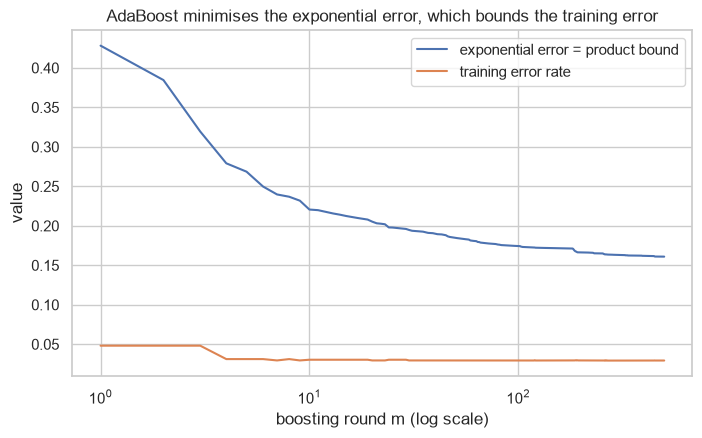

In [7]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(trace.index, trace["exponential error"], label="exponential error = product bound")
ax.plot(trace.index, trace["training error"], label="training error rate")
ax.set_xscale("log"); ax.set_xlabel("boosting round m (log scale)"); ax.set_ylabel("value")
ax.set_title("AdaBoost minimises the exponential error, which bounds the training error")
ax.legend()
plt.savefig("figures/pbl4/fig01_exponential_error.png", dpi=150, bbox_inches="tight")
plt.show()

**Observation:** - **Our AdaBoost is the library's AdaBoost.** All **500 of 500** stumps use the same feature and threshold, $\alpha_m$ and $\epsilon_m$ agree to within **4.4e-15** (rounding error), and the test predictions are **identical**.
- **The exponential error equals the product bound** $\prod 2\sqrt{\epsilon_m(1-\epsilon_m)}$ to within **4.4e-16**, exactly as A.3 says. It falls from **0.428** after one round to **0.161** after 500.
- **The training error stays below it** at every round: from **4.8%** to **2.9%**.
- After about 50 rounds the training error stops improving (2.94% to 2.93%) while the exponential error keeps falling (0.185 to 0.161). Boosting keeps pushing correctly classified patients further from the boundary (bigger margins), which is what improves the probabilities and the ranking in C.4.

## C.4 From weak to strong: performance round by round
`staged_decision_function` gives the boosted vote after every round, so we can watch a single weak stump turn into a strong classifier.

     test ROC-AUC  test error  training error
1          0.7373      0.0463          0.0481
5          0.9515      0.0301          0.0312
10         0.9642      0.0291          0.0303
50         0.9707      0.0284          0.0294
100        0.9725      0.0287          0.0294
200        0.9753      0.0289          0.0295
500        0.9768      0.0288          0.0293


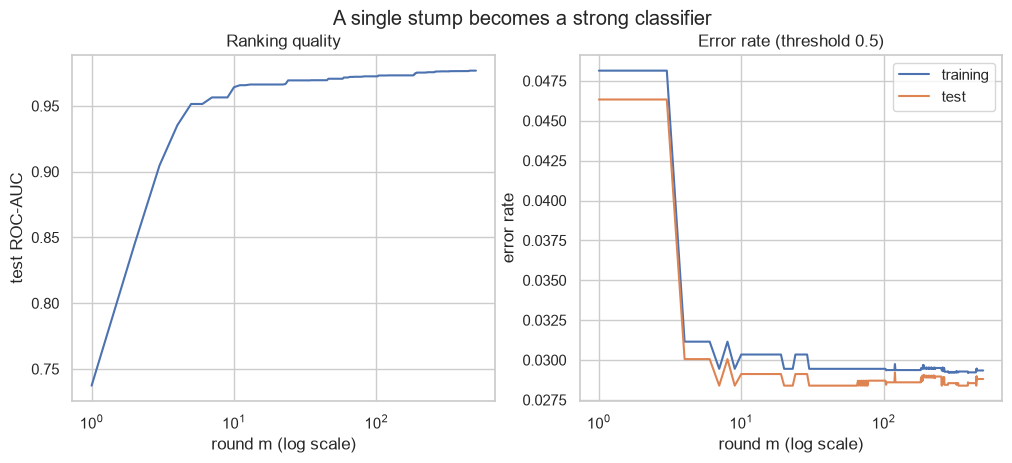

In [8]:
staged_test_auc = [roc_auc_score(y_test, d) for d in ada.staged_decision_function(Xte)]
staged_test_err = [np.mean((d > 0).astype(int) != y_test) for d in ada.staged_decision_function(Xte)]
staged = pd.DataFrame({"test ROC-AUC": staged_test_auc, "test error": staged_test_err,
                       "training error": trace["training error"].to_numpy()}, index=range(1, N_ROUNDS + 1))
print(staged.iloc[[0, 4, 9, 49, 99, 199, 499]].round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(staged.index, staged["test ROC-AUC"], color="C0")
axes[0].set_xscale("log"); axes[0].set_xlabel("round m (log scale)"); axes[0].set_ylabel("test ROC-AUC")
axes[0].set_title("Ranking quality")
axes[1].plot(staged.index, staged["training error"], label="training")
axes[1].plot(staged.index, staged["test error"], label="test")
axes[1].set_xscale("log"); axes[1].set_xlabel("round m (log scale)"); axes[1].set_ylabel("error rate")
axes[1].set_title("Error rate (threshold 0.5)"); axes[1].legend()
plt.suptitle("A single stump becomes a strong classifier")
plt.savefig("figures/pbl4/fig02_weak_to_strong.png", dpi=150, bbox_inches="tight")
plt.show()

**Observation:** - **Weak to strong:** test ROC-AUC climbs from **0.737** (one stump) to **0.952** after 5 rounds, **0.964** after 10 and **0.977** after 500.
- The test error falls from **4.63%** to **2.88%**, and it stays close to the training error (2.93%) all the way. **No overfitting** in 500 rounds: each stump is so simple that adding more of them barely adds variance.

## C.5 Who does boosting focus on?
After 500 rounds the data weights $w_n$ show which patients the committee found hardest. We take the 1% heaviest training patients and compare them with the other diabetic and non-diabetic patients.

In [9]:
heavy = hand_w >= np.quantile(hand_w, 0.99)
print("The heaviest 1%% of patients (%d) hold %.1f%% of the total weight" % (heavy.sum(), hand_w[heavy].sum() * 100))
print("Diabetic share among them: %.3f (overall %.3f)" % (y_train[heavy].mean(), y_train.mean()))
cols = ["HbA1c_level", "blood_glucose_level", "age", "bmi"]
groups = {"heaviest 1%": heavy,
          "other diabetic": ~heavy & (y_train == 1),
          "other non-diabetic": ~heavy & (y_train == 0)}
compare = pd.DataFrame({k: X_train.loc[m, cols].median() for k, m in groups.items()})
compare.loc["patients"] = [m.sum() for m in groups.values()]
compare.loc["below both cut-offs*"] = [np.mean((X_train.loc[m, "HbA1c_level"] < 6.5) &
                                               (X_train.loc[m, "blood_glucose_level"] < 200)) for m in groups.values()]
print("* share with HbA1c < 6.5 and glucose < 200, i.e. not diagnosable by the standard clinical cut-offs")
compare.round(3)

The heaviest 1% of patients (774) hold 28.4% of the total weight
Diabetic share among them: 1.000 (overall 0.088)
* share with HbA1c < 6.5 and glucose < 200, i.e. not diagnosable by the standard clinical cut-offs


,heaviest 1%,other diabetic,other non-diabetic
HbA1c_level,6.100,6.800,5.800
blood_glucose_level,155.000,200.000,140.000
age,52.000,64.000,40.000
bmi,26.500,30.755,26.500
patients,774.000,6012.000,70130.000
below both cut-offs*,0.636,0.158,0.768


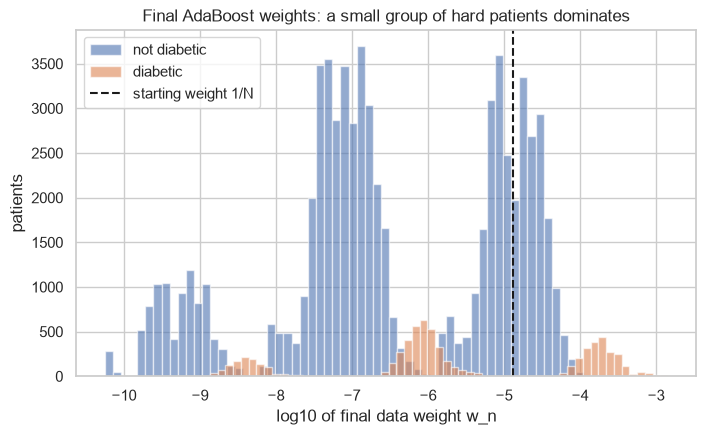

In [10]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(np.log10(hand_w[y_train == 0]), bins=60, alpha=0.6, label="not diabetic")
ax.hist(np.log10(hand_w[y_train == 1]), bins=60, alpha=0.6, label="diabetic")
ax.axvline(np.log10(1 / len(hand_w)), color="k", ls="--", label="starting weight 1/N")
ax.set_xlabel("log10 of final data weight w_n"); ax.set_ylabel("patients")
ax.set_title("Final AdaBoost weights: a small group of hard patients dominates")
ax.legend()
plt.savefig("figures/pbl4/fig03_data_weights.png", dpi=150, bbox_inches="tight")
plt.show()

**Observation:** - **The heaviest 1% of patients (774) hold 28.4% of all the weight**, and **every one of them is diabetic**.
- They are the **hard cases for screening**: their median HbA1c is **6.1** and glucose **155**, against **6.8** and **200** for the other diabetic patients. **63.6%** of them are below both clinical cut-offs, against **15.8%** of the other diabetic patients. In other words, boosting concentrates on diabetic patients whose lab values look almost normal.
- The histogram shows the same thing: diabetic patients split into an easy group, whose weight shrank far below 1/N, and a hard group, whose weight grew 10 to 100 times.

## C.6 Turning the boosted vote into a probability
`predict_proba` of scikit-learn's AdaBoost divides the vote by $\sum_m \alpha_m$ before converting it, which squeezes every probability towards 0.5. A.3 says the correct conversion is $p = \sigma\big(\sum_m \alpha_m y_m(x)\big)$, because the vote estimates the log-odds. We compare both, and draw the error functions of A.3.

Check: this vote equals our hand-written vote: True
                         Log loss  Brier score  ROC-AUC
predict_proba (library)    0.4355       0.1290   0.9768
sigmoid of vote (A.3)      0.0833       0.0237   0.9768


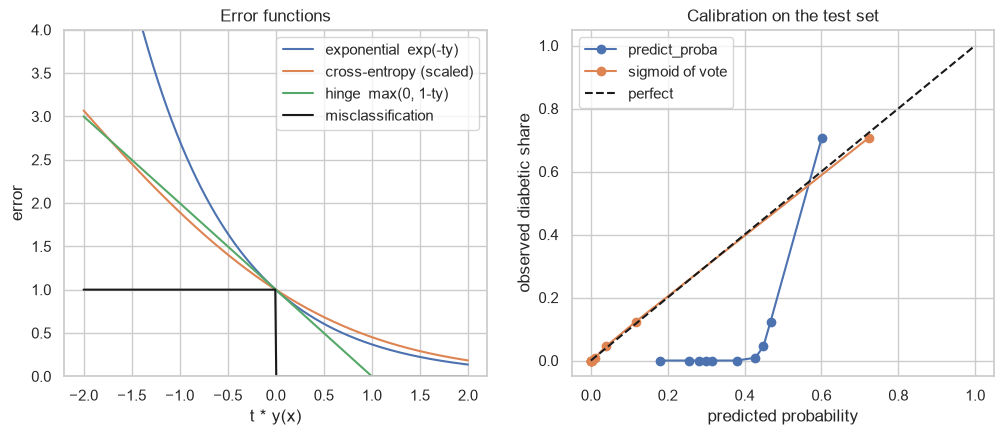

In [11]:
# For two classes, scikit-learn's decision_function returns 2 * sum(alpha_m * y_m) / sum(alpha_m),
# so multiply by sum(alpha_m) / 2 to get back the plain vote of A.2.
vote_test = ada.decision_function(Xte) * ada.estimator_weights_.sum() / 2
p_ada_raw = ada.predict_proba(Xte)[:, 1]
p_ada = expit(vote_test)
print("Check: this vote equals our hand-written vote: %s" % np.allclose(vote_test, hand_vote_test))
calib = pd.DataFrame({"Log loss": [log_loss(y_test, p_ada_raw), log_loss(y_test, p_ada)],
                      "Brier score": [brier_score_loss(y_test, p_ada_raw), brier_score_loss(y_test, p_ada)],
                      "ROC-AUC": [roc_auc_score(y_test, p_ada_raw), roc_auc_score(y_test, p_ada)]},
                     index=["predict_proba (library)", "sigmoid of vote (A.3)"])
print(calib.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
z = np.linspace(-2, 2, 400)
axes[0].plot(z, np.exp(-z), label="exponential  exp(-ty)")
axes[0].plot(z, np.log(1 + np.exp(-z)) / np.log(2), label="cross-entropy (scaled)")
axes[0].plot(z, np.maximum(0, 1 - z), label="hinge  max(0, 1-ty)")
axes[0].plot(z, (z < 0).astype(float), label="misclassification", color="k")
axes[0].set_ylim(0, 4); axes[0].set_xlabel("t * y(x)"); axes[0].set_ylabel("error")
axes[0].set_title("Error functions"); axes[0].legend()
for p, lab in [(p_ada_raw, "predict_proba"), (p_ada, "sigmoid of vote")]:
    frac, mean_p = calibration_curve(y_test, p, n_bins=10, strategy="quantile")
    axes[1].plot(mean_p, frac, "o-", label=lab)
axes[1].plot([0, 1], [0, 1], "k--", label="perfect")
axes[1].set_xlabel("predicted probability"); axes[1].set_ylabel("observed diabetic share")
axes[1].set_title("Calibration on the test set"); axes[1].legend()
plt.savefig("figures/pbl4/fig04_error_functions_calibration.png", dpi=150, bbox_inches="tight")
plt.show()

**Observation:** - **The ranking is identical** (ROC-AUC **0.9768** both ways), because both are increasing functions of the same vote.
- **The probabilities are not.** The library's `predict_proba` squeezes everything into roughly 0.2 to 0.6, which gives a log loss of **0.436** and a Brier score of **0.129**. Using A.3, $p = \sigma(\text{vote})$, gives **0.083** and **0.024**, and the calibration curve lies on the diagonal.
- This confirms the theory: minimising the exponential error makes the boosted vote an estimate of the **log-odds**, so it can be turned into a well-calibrated risk.

## C.7 Comparison: single models, bagging and boosting
- **Random forest (bagging):** 300 deep trees on bootstrap samples, equal vote.
- **AdaBoost:** 500 stumps, exponential error, probabilities from C.6.
- **Gradient boosting:** scikit-learn's `HistGradientBoostingClassifier`. It is boosting with the **cross-entropy** error instead of the exponential one, and with small trees instead of stumps.

In [12]:
t0 = time.time()
rf = RandomForestClassifier(n_estimators=300, min_samples_leaf=5, n_jobs=-1, random_state=RANDOM_STATE).fit(Xtr, y_train)
evaluate("Random forest (bagging)", rf.predict_proba(Xte)[:, 1])
evaluate("AdaBoost, 500 stumps", p_ada)
gb = HistGradientBoostingClassifier(random_state=RANDOM_STATE).fit(Xtr, y_train)
evaluate("Gradient boosting (cross-entropy)", gb.predict_proba(Xte)[:, 1])
print("Fitted in %.1f s" % (time.time() - t0))
comparison = pd.DataFrame(results).T
comparison.round(4)

Fitted in 6.9 s


,ROC-AUC,Avg precision,Log loss,Recall,Precision,F1
Single stump,0.7373,0.5210,0.1856,0.4746,1.0000,0.6437
CART tree (depth 6),0.9618,0.8248,0.0933,0.6781,1.0000,0.8082
Random forest (bagging),0.9700,0.8705,0.0931,0.6804,0.9974,0.8090
"AdaBoost, 500 stumps",0.9768,0.8793,0.0833,0.6887,0.9782,0.8083
Gradient boosting (cross-entropy),0.9770,0.8811,0.0832,0.6934,0.9776,0.8113


For reference, the tuned PBL 1 random forest (balanced class weights, threshold 0.7) reached ROC-AUC 0.974 on the same test split.

**Observation:** - **Boosting beats bagging here.** AdaBoost on stumps reaches ROC-AUC **0.977** and average precision **0.879**, against **0.970** and **0.871** for the random forest and **0.962** for one tree. Gradient boosting (cross-entropy error) is level with AdaBoost (**0.977**, **0.881**).
- **Probabilities:** AdaBoost's log loss (**0.083**) matches gradient boosting (**0.083**) and beats the random forest (**0.093**).
- 500 stumps beat the tuned PBL 1 random forest (0.974) on the same test split.
- At the default threshold 0.5 every model has very high precision (0.98 to 1.00) but finds only **68 to 69%** of diabetic patients, because only 8.8% of patients are positive. A screening tool would lower the threshold, as PBL 1 did.

## C.8 Robustness to wrong labels
The exponential error punishes a misclassified point exponentially, so the theory warns that boosting is **sensitive to outliers and mislabelled data**. We test it: flip the label of 5% and then 10% of the **training** patients at random, refit, and evaluate on the clean test set. We also measure how much of AdaBoost's final weight ends up on the flipped patients.

In [13]:
rows = []
rng = np.random.RandomState(RANDOM_STATE)
noise_runs = {}
for frac in [0.0, 0.05, 0.10]:
    y_noisy = y_train.copy()
    flipped = rng.choice(len(y_noisy), int(frac * len(y_noisy)), replace=False)
    y_noisy[flipped] = 1 - y_noisy[flipped]
    a = AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=1), n_estimators=N_ROUNDS,
                           random_state=RANDOM_STATE).fit(Xtr, y_noisy)
    r = RandomForestClassifier(n_estimators=300, min_samples_leaf=5, n_jobs=-1, random_state=RANDOM_STATE).fit(Xtr, y_noisy)
    g = HistGradientBoostingClassifier(random_state=RANDOM_STATE).fit(Xtr, y_noisy)
    noise_runs[frac] = (a, flipped, y_noisy)
    rows.append({"flipped": "%d%%" % (frac * 100),
                 "AdaBoost": roc_auc_score(y_test, a.decision_function(Xte)),
                 "Random forest": roc_auc_score(y_test, r.predict_proba(Xte)[:, 1]),
                 "Gradient boosting": roc_auc_score(y_test, g.predict_proba(Xte)[:, 1])})
noise_table = pd.DataFrame(rows).set_index("flipped")
print("Test ROC-AUC (clean test labels):")
print(noise_table.round(4))

_, flipped5, y5 = noise_runs[0.05]
_, _, _, w5, _ = adaboost_by_hand(Xtr, y5, 200, RANDOM_STATE)
print("\nWith 5%% flipped labels, after 200 rounds the flipped patients hold %.1f%% of AdaBoost's weight" % (w5[flipped5].sum() * 100))

Test ROC-AUC (clean test labels):
         AdaBoost  Random forest  Gradient boosting
flipped                                            
0%         0.9768         0.9700             0.9770
5%         0.9692         0.9554             0.9735
10%        0.9681         0.9473             0.9723



With 5% flipped labels, after 200 rounds the flipped patients hold 36.2% of AdaBoost's weight


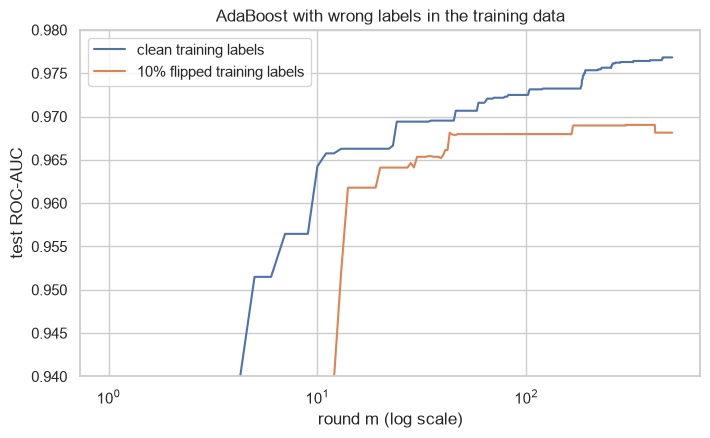

Best round with 10% noise: 300 (AUC 0.9690); after 500 rounds: 0.9681


In [14]:
a10 = noise_runs[0.10][0]
noisy_auc = [roc_auc_score(y_test, d) for d in a10.staged_decision_function(Xte)]
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(range(1, N_ROUNDS + 1), staged_test_auc, label="clean training labels")
ax.plot(range(1, N_ROUNDS + 1), noisy_auc, label="10% flipped training labels")
ax.set_xscale("log"); ax.set_xlabel("round m (log scale)"); ax.set_ylabel("test ROC-AUC")
ax.set_ylim(0.94, 0.98)
ax.set_title("AdaBoost with wrong labels in the training data")
ax.legend()
plt.savefig("figures/pbl4/fig05_label_noise.png", dpi=150, bbox_inches="tight")
plt.show()
print("Best round with 10%% noise: %d (AUC %.4f); after %d rounds: %.4f" % (
    int(np.argmax(noisy_auc)) + 1, max(noisy_auc), N_ROUNDS, noisy_auc[-1]))

**Observation:** - **The mechanism the theory warns about is real:** with 5% of labels flipped, after 200 rounds the flipped patients hold **36.2%** of AdaBoost's total weight, more than 7 times their share. The exponential error makes boosting chase the wrong labels.
- **But the damage on the clean test set is small:** AdaBoost loses **0.009** of ROC-AUC with 10% noise (0.977 to 0.968). The **random forest loses more (0.023)**, because its deep trees memorise individual wrong labels, while a stump is too simple to memorise any one patient.
- **Gradient boosting is the most robust (loses 0.005).** Its cross-entropy error grows only linearly for badly misclassified points, against exponentially for AdaBoost, exactly the difference shown in the error-function plot.
- With 10% noise, AdaBoost's test ROC-AUC peaks at round **300 (0.9690)** and then slips (**0.9681** at 500), while on clean labels it is still rising. That is the first sign of boosting fitting the noise; stopping early would help.

## C.9 What the committees rely on
AdaBoost's feature importance adds up the improvement of every stump that uses a feature, weighted by $\alpha_m$. We compare it with the random forest's importance.

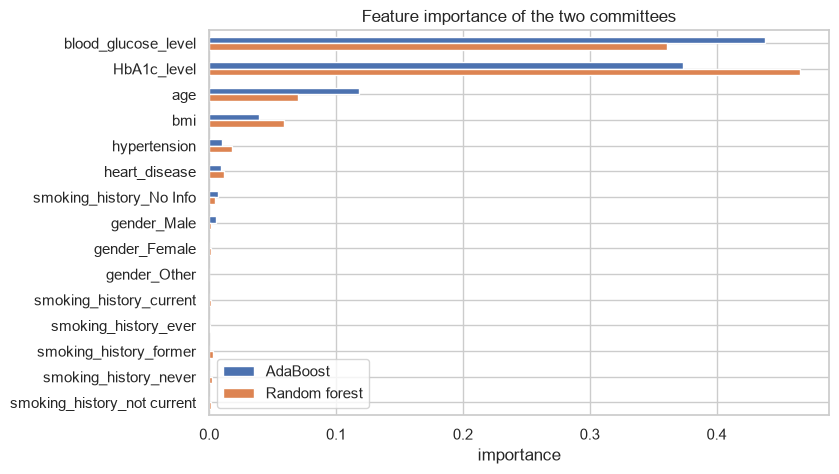

,AdaBoost,Random forest,stumps using it (of 500)
blood_glucose_level,0.438,0.361,219
HbA1c_level,0.373,0.465,179
age,0.118,0.070,88
bmi,0.039,0.059,7
hypertension,0.010,0.018,2
heart_disease,0.009,0.012,3
smoking_history_No Info,0.007,0.004,1
gender_Male,0.005,0.002,1
gender_Female,0.000,0.002,0
gender_Other,0.000,0.000,0


In [15]:
imp = pd.DataFrame({"AdaBoost": ada.feature_importances_, "Random forest": rf.feature_importances_}, index=features)
imp = imp.sort_values("AdaBoost", ascending=False)
stump_counts = pd.Series([features[e.tree_.feature[0]] for e in ada.estimators_]).value_counts()
imp["stumps using it (of 500)"] = stump_counts.reindex(imp.index).fillna(0).astype(int)
imp.plot(kind="barh", y=["AdaBoost", "Random forest"], figsize=(8, 5))
plt.gca().invert_yaxis(); plt.xlabel("importance")
plt.title("Feature importance of the two committees")
plt.savefig("figures/pbl4/fig06_feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()
imp.round(3)

**Observation:** - **Blood glucose (0.438)** and **HbA1c (0.373)** carry most of AdaBoost's decisions: 398 of the 500 stumps split on one of them. **Age** follows (0.118, 88 stumps), then BMI (0.039).
- Smoking and gender are almost never used. The random forest ranks the same four features on top, with HbA1c first.
- This is the same order of risk factors that PBL 1 found with odds ratios and permutation importance, now found by a completely different method.

# Section D: Bayesian Model Averaging

## D.1 The model space
We group the inputs into 8 features (gender and smoking count as one group each, since their one-hot columns belong together):

`age, hypertension, heart_disease, bmi, HbA1c, glucose, gender, smoking`

Every subset of these defines one logistic regression, so there are $2^8 = 256$ candidate models, from "no features" (always predict the base rate) to "all 8". For each model we compute, **by hand**:
$$\ln L_k = \sum_n \big[t_n \ln p_n + (1-t_n)\ln(1-p_n)\big], \qquad \mathrm{BIC}_k = -2\ln L_k + p_k \ln N$$
where $p_k$ is the number of coefficients plus the intercept. The logistic regressions are fitted with a very weak penalty (`C = 1e6`), so they are effectively maximum-likelihood fits, which BIC assumes.

In [16]:
GROUPS = {"age": ["age"], "hypertension": ["hypertension"], "heart_disease": ["heart_disease"],
          "bmi": ["bmi"], "HbA1c": ["HbA1c_level"], "glucose": ["blood_glucose_level"],
          "gender": [c for c in features if c.startswith("gender_")][1:],          # one category dropped
          "smoking": [c for c in features if c.startswith("smoking_history_")][1:]}
mu, sd = X_train.mean(), X_train.std()
Z_train, Z_test = (X_train - mu) / sd, (X_test - mu) / sd
MODELS = [S for k in range(len(GROUPS) + 1) for S in itertools.combinations(GROUPS, k)]
print("Candidate models:", len(MODELS))

def fit_model_space(Z, y, Z_eval):
    # Fit all 256 logistic regressions; return BIC and test-set probabilities of each.
    bic, probs = np.zeros(len(MODELS)), np.zeros((len(MODELS), len(Z_eval)))
    for i, S in enumerate(MODELS):
        cols = [c for g in S for c in GROUPS[g]]
        if cols:
            lr = LogisticRegression(C=1e6, max_iter=5000).fit(Z[cols], y)
            p_fit, probs[i] = lr.predict_proba(Z[cols])[:, 1], lr.predict_proba(Z_eval[cols])[:, 1]
        else:
            p_fit, probs[i] = np.full(len(y), y.mean()), np.full(len(Z_eval), y.mean())
        p_fit = np.clip(p_fit, 1e-12, 1 - 1e-12)
        loglik = np.sum(y * np.log(p_fit) + (1 - y) * np.log(1 - p_fit))
        bic[i] = -2 * loglik + (len(cols) + 1) * np.log(len(y))
    return bic, probs

def posterior_weights(bic):
    w = np.exp(-(bic - bic.min()) / 2)        # subtract the minimum to avoid underflow
    return w / w.sum()

def inclusion_probability(w):
    return pd.Series({g: w[[g in S for S in MODELS]].sum() for g in GROUPS})

t0 = time.time()
bic_full, probs_full = fit_model_space(Z_train, y_train, Z_test)
w_full = posterior_weights(bic_full)
print("Fitted 256 models on %d patients in %.1f s" % (len(y_train), time.time() - t0))

Candidate models: 256


Fitted 256 models on 76916 patients in 28.6 s


## D.2 The posterior on the full training set (76,916 patients)

In [17]:
order = np.argsort(bic_full)
top = pd.DataFrame({"features left out": [", ".join(sorted(set(GROUPS) - set(MODELS[i]))) or "(none)" for i in order[:6]],
                    "BIC": bic_full[order[:6]],
                    "BIC - best": bic_full[order[:6]] - bic_full[order[0]],
                    "posterior p(M | D)": w_full[order[:6]]}, index=range(1, 7))
print(top.to_string(float_format=lambda v: "%.4g" % v))
print("\nPosterior inclusion probabilities:")
print(inclusion_probability(w_full).round(4).to_dict())

p_bma_full = w_full @ probs_full
print()
print(evaluate("BMA, 256 logistic models", p_bma_full).to_dict())
print(evaluate("Equal average of 256 logistic models", probs_full.mean(axis=0)).to_dict())

       features left out       BIC  BIC - best  posterior p(M | D)
1                 (none) 1.802e+04           0                   1
2                 gender 1.805e+04          32           1.125e-07
3                smoking 1.807e+04       57.04           4.112e-13
4        gender, smoking 1.811e+04       89.73           3.278e-20
5          heart_disease 1.812e+04         105           1.575e-23
6  gender, heart_disease 1.817e+04       155.6           1.653e-34

Posterior inclusion probabilities:
{'age': 1.0, 'hypertension': 1.0, 'heart_disease': 1.0, 'bmi': 1.0, 'HbA1c': 1.0, 'glucose': 1.0, 'gender': 1.0, 'smoking': 1.0}

{'ROC-AUC': 0.9598, 'Avg precision': 0.8174, 'Log loss': 0.1174, 'Recall': 0.6397, 'Precision': 0.8708, 'F1': 0.7376}
{'ROC-AUC': 0.9498, 'Avg precision': 0.8111, 'Log loss': 0.1572, 'Recall': 0.4239, 'Precision': 0.9849, 'F1': 0.5927}


**Observation:** - **The posterior collapses onto one model.** The model with all 8 feature groups has the lowest BIC. The next best (dropping gender) is **32 BIC units** worse, which makes it $e^{-16}$, about **1 in 9 million**, less probable. Every feature has posterior inclusion probability **1.000**.
- So with 76,916 patients **BMA is the same as choosing the single best model**: ROC-AUC **0.960**, log loss **0.117**.
- **Averaging all 256 models equally is clearly worse** (ROC-AUC **0.950**, log loss **0.157**, recall 0.42): it gives the same vote to weak models, such as the ones without any blood test, as to the good ones.
- All of these logistic models stay below AdaBoost (0.977), because a linear model of the log-odds cannot capture the sharp threshold effects that the stumps find.

## D.3 Bayesian model averaging when data is scarce
BMA matters when the data cannot tell the models apart. We repeat the whole procedure on random training subsets of 200, 500, 1,000 and 5,000 patients (10 different random subsets for each size) and always evaluate on the full test set (19,230 patients). For each run we compare:
- **BMA:** the posterior-weighted average of all 256 models
- **Best single model:** only the model with the lowest BIC (classic model selection)
- **Equal average:** all 256 models with the same weight (a committee that ignores the evidence)

In [18]:
t0 = time.time()
rows, pip_small = [], []
for n in [200, 500, 1000, 5000]:
    for seed in range(10):
        idx = np.random.RandomState(seed).choice(len(y_train), n, replace=False)
        b, P = fit_model_space(Z_train.iloc[idx], y_train[idx], Z_test)
        w = posterior_weights(b)
        best = np.argmin(b)
        rows.append({"n": n, "seed": seed,
                     "top model weight": w.max(),
                     "models for 95% of weight": int(np.searchsorted(np.cumsum(np.sort(w)[::-1]), 0.95) + 1),
                     "AUC BMA": roc_auc_score(y_test, w @ P), "AUC best model": roc_auc_score(y_test, P[best]),
                     "AUC equal avg": roc_auc_score(y_test, P.mean(axis=0)),
                     "LL BMA": log_loss(y_test, w @ P), "LL best model": log_loss(y_test, P[best]),
                     "LL equal avg": log_loss(y_test, P.mean(axis=0))})
        if n == 200:
            pip_small.append(inclusion_probability(w))
print("400 runs of 256 models each... done in %.0f s" % (time.time() - t0))
small = pd.DataFrame(rows)
summary = small.groupby("n").mean().drop(columns="seed")
summary["BMA beats best model (AUC), runs of 10"] = small.assign(win=small["AUC BMA"] > small["AUC best model"]).groupby("n")["win"].sum()
summary.round(4)

400 runs of 256 models each... done in 245 s


,top model weight,models for 95% of weight,AUC BMA,AUC best model,AUC equal avg,LL BMA,LL best model,LL equal avg,"BMA beats best model (AUC), runs of 10"
n,,,,,,,,,
200,0.4733,8.1,0.9388,0.9372,0.9312,0.1587,0.2343,0.1656,6
500,0.5050,6.1,0.9532,0.9515,0.9434,0.1269,0.1312,0.1593,7
1000,0.5415,4.7,0.9555,0.9556,0.9464,0.1233,0.1239,0.1579,5
5000,0.7724,2.4,0.9587,0.9587,0.9490,0.1187,0.1189,0.1571,9


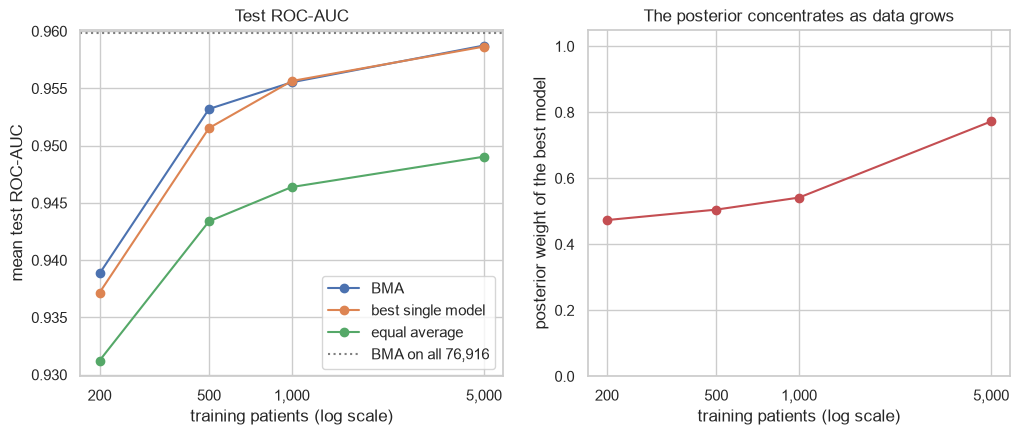

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sizes = summary.index.to_numpy()
for col, lab in [("AUC BMA", "BMA"), ("AUC best model", "best single model"), ("AUC equal avg", "equal average")]:
    axes[0].plot(sizes, summary[col], "o-", label=lab)
axes[0].axhline(results["BMA, 256 logistic models"]["ROC-AUC"], color="grey", ls=":", label="BMA on all 76,916")
axes[0].set_xscale("log"); axes[0].set_xlabel("training patients (log scale)"); axes[0].set_ylabel("mean test ROC-AUC")
axes[0].set_title("Test ROC-AUC"); axes[0].legend()
axes[1].plot(sizes, summary["top model weight"], "o-", color="C3")
axes[1].set_xscale("log"); axes[1].set_ylim(0, 1.05)
axes[1].set_xlabel("training patients (log scale)"); axes[1].set_ylabel("posterior weight of the best model")
axes[1].set_title("The posterior concentrates as data grows")
for ax in axes:
    ax.minorticks_off(); ax.set_xticks(sizes); ax.set_xticklabels(["{:,}".format(s) for s in sizes])
plt.savefig("figures/pbl4/fig07_bma_sample_size.png", dpi=150, bbox_inches="tight")
plt.show()

**Observation:** - **With little data, the posterior spreads out.** At 200 patients the best model gets only **47%** of the weight, and **8 models** are needed to cover 95% of it. At 5,000 patients the best model already has **77%** and 2.4 models cover 95%.
- **The clearest gain is in the probabilities.** At 200 patients BMA's test log loss is **0.159**, against **0.234** for the best single model, which is overconfident because it ignores that other models were almost as plausible. At 500 patients the gap is smaller (0.127 vs 0.131), and from 1,000 patients on the two are the same.
- **The ranking gain is small** (ROC-AUC 0.939 vs 0.937 at 200 patients; BMA wins in 6 and 7 of the 10 runs at 200 and 500). At 5,000 patients BMA wins 9 of 10 runs, but only in the fourth decimal.
- **Equal averaging is the worst at every size**, so the evidence weights, not the averaging itself, are what makes BMA work.

## D.4 Which features does the evidence support? (n = 200)
With little data the posterior inclusion probabilities are the explainable output of BMA: the probability, given the data, that each feature belongs in the model. Mean over the 10 runs with 200 patients:

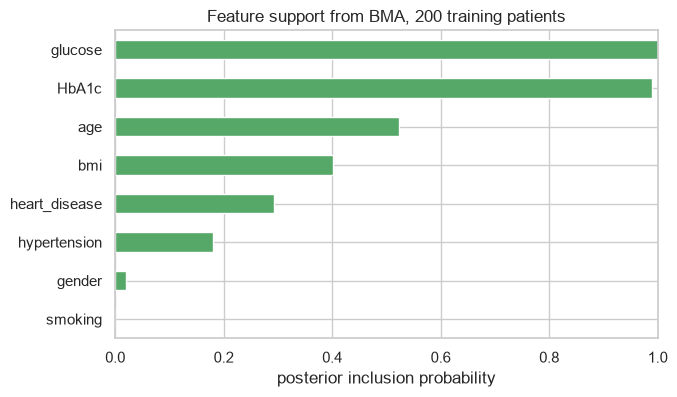

glucose          1.000
HbA1c            0.989
age              0.524
bmi              0.402
heart_disease    0.293
hypertension     0.181
gender           0.020
smoking          0.000
dtype: float64

In [20]:
pip200 = pd.concat(pip_small, axis=1).mean(axis=1).sort_values(ascending=False)
pip200.plot(kind="barh", figsize=(7, 4), color="C2")
plt.gca().invert_yaxis(); plt.xlim(0, 1)
plt.xlabel("posterior inclusion probability"); plt.title("Feature support from BMA, 200 training patients")
plt.savefig("figures/pbl4/fig08_inclusion_probability.png", dpi=150, bbox_inches="tight")
plt.show()
pip200.round(3)

**Observation:** - **Glucose (1.00) and HbA1c (0.99)** are certain even with only 200 patients.
- **Age (0.52) and BMI (0.40)** are uncertain: the data supports them about half the time. Heart disease (0.29) and hypertension (0.18) get some support.
- **Gender (0.02) and smoking (0.00)** are not supported.
- This is the same order as AdaBoost's feature importance in C.9, but BMA also says **how sure** the evidence is about each feature. On the full data every inclusion probability rises to 1.00, so with enough patients even the small effects become certain.

## D.5 BMA versus ensembles, side by side

| | Bayesian model averaging | Boosting / bagging ensembles |
|---|---|---|
| Assumption | one of the candidate models is true | no single member is assumed true |
| Weights | posterior probability $p(M_k \mid D)$ | boosting: $\alpha_m$ from training error; bagging: equal |
| With more data | weight concentrates on one model (BMA becomes model selection) | the committee keeps all members and grows richer |
| Gain is largest when | data is small and models are hard to tell apart | the base models are weak but different |
| In this notebook | posterior weight 1.000 on one model with 76,916 patients; helps only with 200 to 500 patients (log loss 0.159 vs 0.234) | 500 stumps reach ROC-AUC 0.977, better than any single model or than BMA (0.960) |

# Section E: Realistic Screening Without Blood Tests

## E.1 Why this matters
In this dataset the diabetes label follows HbA1c and glucose very closely: the very first stump (HbA1c > 6.70) is never wrong about the patients it flags. Those two values are part of how diabetes is **diagnosed**, so a model that uses them is partly **circular**, and the ROC-AUC of about 0.977 in Sections C and D overstates what a screening tool could do. The PBL 1 Kaggle notebook made the same point.

The realistic question for **early screening** is: *before any blood test*, can we flag patients at risk from age, BMI, blood pressure, heart disease, gender and smoking? We repeat the key comparison on exactly that feature set, with the same split.

- **Same models:** stump, CART tree, random forest, AdaBoost (500 stumps, probabilities from $\sigma(\text{vote})$), gradient boosting, plus a plain logistic regression.
- **Bayesian model averaging without blood tests:** the 64 of our 256 candidate models that use neither HbA1c nor glucose already exist from D.1, so we renormalise their posterior weights among themselves. This is BMA over the smaller model space; nothing is refitted.

In [21]:
NO_LAB = [c for c in features if c not in ("HbA1c_level", "blood_glucose_level")]
cols_nl = [features.index(c) for c in NO_LAB]
Xtr_nl, Xte_nl = Xtr[:, cols_nl], Xte[:, cols_nl]
print("Features without blood tests (%d columns):" % len(NO_LAB), NO_LAB)

results_nl = {}
def evaluate_nl(name, p):
    results_nl[name] = {"ROC-AUC": roc_auc_score(y_test, p),
                        "Avg precision": average_precision_score(y_test, p),
                        "Log loss": log_loss(y_test, np.clip(p, 1e-12, 1 - 1e-12))}

t0 = time.time()
stump_nl = DecisionTreeClassifier(max_depth=1, random_state=RANDOM_STATE).fit(Xtr_nl, y_train)
evaluate_nl("Single stump", stump_nl.predict_proba(Xte_nl)[:, 1])
tree_nl = DecisionTreeClassifier(max_depth=6, random_state=RANDOM_STATE).fit(Xtr_nl, y_train)
evaluate_nl("CART tree (depth 6)", tree_nl.predict_proba(Xte_nl)[:, 1])
rf_nl = RandomForestClassifier(n_estimators=300, min_samples_leaf=5, n_jobs=-1, random_state=RANDOM_STATE).fit(Xtr_nl, y_train)
evaluate_nl("Random forest (bagging)", rf_nl.predict_proba(Xte_nl)[:, 1])
ada_nl = AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=1), n_estimators=N_ROUNDS,
                            random_state=RANDOM_STATE).fit(Xtr_nl, y_train)
vote_nl = ada_nl.decision_function(Xte_nl) * ada_nl.estimator_weights_.sum() / 2
evaluate_nl("AdaBoost, 500 stumps", expit(vote_nl))
gb_nl = HistGradientBoostingClassifier(random_state=RANDOM_STATE).fit(Xtr_nl, y_train)
evaluate_nl("Gradient boosting (cross-entropy)", gb_nl.predict_proba(Xte_nl)[:, 1])
lr_cols = [c for c in NO_LAB]
lr_nl = LogisticRegression(C=1e6, max_iter=5000).fit(Z_train[lr_cols], y_train)
evaluate_nl("Logistic regression (all 6 groups)", lr_nl.predict_proba(Z_test[lr_cols])[:, 1])

no_lab_models = np.array(["HbA1c" not in S and "glucose" not in S for S in MODELS])
w_nl = posterior_weights(bic_full[no_lab_models])
evaluate_nl("BMA, 64 models without blood tests", w_nl @ probs_full[no_lab_models])
print("Fitted in %.1f s" % (time.time() - t0))

screening = pd.DataFrame(results_nl).T
screening["ROC-AUC with blood tests"] = [results[k]["ROC-AUC"] if k in results else np.nan for k in screening.index]
screening.loc["Logistic regression (all 6 groups)", "ROC-AUC with blood tests"] = np.nan
screening.loc["BMA, 64 models without blood tests", "ROC-AUC with blood tests"] = results["BMA, 256 logistic models"]["ROC-AUC"]
screening["drop"] = screening["ROC-AUC with blood tests"] - screening["ROC-AUC"]
screening.round(4)

Features without blood tests (13 columns): ['age', 'hypertension', 'heart_disease', 'bmi', 'gender_Female', 'gender_Male', 'gender_Other', 'smoking_history_No Info', 'smoking_history_current', 'smoking_history_ever', 'smoking_history_former', 'smoking_history_never', 'smoking_history_not current']


Fitted in 32.7 s


,ROC-AUC,Avg precision,Log loss,ROC-AUC with blood tests,drop
Single stump,0.7055,0.1577,0.2700,0.7373,0.0319
CART tree (depth 6),0.8163,0.2913,0.2420,0.9618,0.1455
Random forest (bagging),0.8041,0.2792,0.2502,0.9700,0.1659
"AdaBoost, 500 stumps",0.8197,0.3008,0.2407,0.9768,0.1571
Gradient boosting (cross-entropy),0.8247,0.3095,0.2389,0.9770,0.1524
Logistic regression (all 6 groups),0.8246,0.3082,0.2394,NaN,NaN
"BMA, 64 models without blood tests",0.8246,0.3081,0.2394,0.9598,0.1352


For reference, the PBL 1 Kaggle notebook's best model without blood tests was a class-balanced logistic regression with ROC-AUC 0.825 on the same test split.

**Observation:** - **Every model loses about 0.15 of ROC-AUC without blood tests.** AdaBoost falls from **0.977 to 0.820**, the random forest from 0.970 to 0.804, gradient boosting from 0.977 to 0.825. Average precision drops from about 0.88 to about **0.30**. Most of the strength in Sections C and D came from HbA1c and glucose, the same values used to diagnose diabetes.
- **Boosting's advantage disappears.** Plain logistic regression (**0.825**) is as good as gradient boosting (**0.825**) and slightly better than AdaBoost (**0.820**). The random forest is now the weakest of the full models (**0.804**): its deep trees fit noise that the simpler models ignore.
- **BMA equals logistic regression (0.825)**: with 76,916 patients the posterior again puts all its weight on the model with all six groups.
- **These numbers match PBL 1:** the class-balanced logistic regression without blood tests reached 0.825 there too.
- **What this means:** ensembles win when the signal has sharp threshold effects, like HbA1c above 6.7. Without blood tests the risk rises smoothly with age and BMI, which a linear model already captures. For a realistic screening tool, the simple and explainable logistic regression is the right choice.

## E.2 What the screening models use
The first AdaBoost stumps and the posterior inclusion probabilities of BMA, both without blood tests.

              feature  threshold  eps_m  alpha_m
round m                                         
1                 age     53.500  0.088    2.335
2                 age     44.500  0.283    0.929
3                 bmi     30.675  0.345    0.641
4                 age     60.500  0.404    0.390
5        hypertension      0.500  0.438    0.248
6                 age     26.500  0.436    0.258

BMA posterior inclusion probabilities without blood tests:
{'age': 1.0, 'hypertension': 1.0, 'heart_disease': 1.0, 'bmi': 1.0, 'gender': 1.0, 'smoking': 1.0}
Top no-blood-test model gets posterior weight 1.000

AdaBoost feature importance without blood tests:
{'age': 0.758, 'bmi': 0.146, 'heart_disease': 0.031, 'hypertension': 0.03, 'smoking_history_No Info': 0.02}


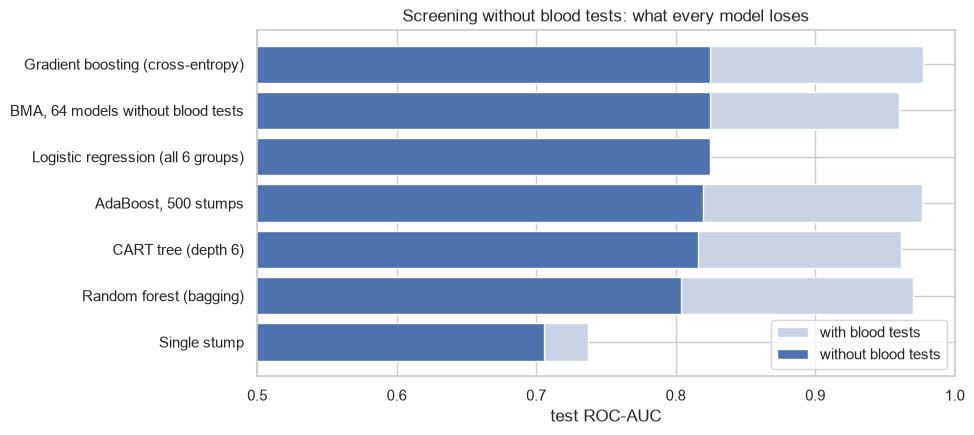

In [22]:
first_nl = pd.DataFrame({"feature": [NO_LAB[e.tree_.feature[0]] for e in ada_nl.estimators_[:6]],
                         "threshold": [e.tree_.threshold[0] for e in ada_nl.estimators_[:6]],
                         "eps_m": ada_nl.estimator_errors_[:6],
                         "alpha_m": ada_nl.estimator_weights_[:6]}, index=range(1, 7))
first_nl.index.name = "round m"
print(first_nl.round(3))

pip_nl = pd.Series({g: w_nl[[g in S for S in np.array(MODELS, dtype=object)[no_lab_models]]].sum()
                    for g in GROUPS if g not in ("HbA1c", "glucose")})
print("\nBMA posterior inclusion probabilities without blood tests:")
print(pip_nl.round(3).to_dict())
print("Top no-blood-test model gets posterior weight %.3f" % w_nl.max())

imp_nl = pd.Series(ada_nl.feature_importances_, index=NO_LAB).sort_values(ascending=False)
print("\nAdaBoost feature importance without blood tests:")
print(imp_nl.head(5).round(3).to_dict())

fig, ax = plt.subplots(figsize=(9, 4.5))
order_nl = screening.sort_values("ROC-AUC").index
ax.barh(order_nl, screening.loc[order_nl, "ROC-AUC with blood tests"], color="#C9D3E3", label="with blood tests")
ax.barh(order_nl, screening.loc[order_nl, "ROC-AUC"], color="C0", label="without blood tests")
ax.set_xlim(0.5, 1.0); ax.set_xlabel("test ROC-AUC")
ax.set_title("Screening without blood tests: what every model loses")
ax.legend(loc="lower right")
plt.savefig("figures/pbl4/fig09_no_blood_tests.png", dpi=150, bbox_inches="tight")
plt.show()

**Observation:** - **Age drives the screening model.** AdaBoost's importance is **0.758** for age and **0.146** for BMI; everything else is below 0.04. The stumps split age at **53.5, 44.5, 60.5 and 26.5**, and BMI at **30.7**, close to the clinical obesity line of 30.
- **The first stump is barely better than "nobody is diabetic".** Its weighted error (**0.088**) is the same as the diabetic share. Without blood tests no single rule separates the classes; the committee has to build risk up from many small steps.
- **BMA keeps all six groups** (every inclusion probability 1.000), so with this much data even the small effects of heart disease, hypertension, gender and smoking are supported.
- The order, age first and then BMI, is the same as the PBL 1 no-blood-test model.

# Section F: Conclusion

- **Boosting turns a weak rule into a strong classifier.** One HbA1c stump (ROC-AUC 0.737) becomes a committee of 500 stumps with ROC-AUC **0.977**, better than one tree (0.962), the random forest (0.970) and the tuned PBL 1 forest (0.974).
- **We understand the algorithm, not just the library.** Our hand-written AdaBoost reproduces scikit-learn exactly (500 of 500 stumps, identical predictions), and the exponential error equals the theoretical product bound to 4e-16.
- **The theory explains the behaviour:** reweighting concentrates on diabetic patients with near-normal lab values; the vote is a log-odds estimate, so $\sigma(\text{vote})$ gives calibrated risks (log loss 0.436 to 0.083); and the exponential error makes AdaBoost chase wrong labels (36% of the weight on 5% flipped labels), although stumps keep the damage smaller than for a random forest.
- **Bayesian model averaging weights models by evidence.** On 76,916 patients the evidence is decisive, so BMA reduces to the single full model. With 200 patients it spreads weight over about 8 models and gives clearly better probabilities than picking one model (log loss 0.159 vs 0.234).
- **Both methods agree on the risk factors:** glucose and HbA1c first, then age and BMI. Smoking and gender add almost nothing.
- **Realistic screening check.** Without HbA1c and glucose every model loses about 0.15 of ROC-AUC (AdaBoost 0.977 to 0.820), and plain logistic regression (0.825) is as good as any ensemble. Boosting pays off when the signal has sharp thresholds; for screening before a blood test the simple, explainable model is enough.

**Limitations**
- **One dataset, one split.** All Section C numbers come from one 80 / 20 split of the Kaggle data. Differences in the third decimal of ROC-AUC between the strong models are within normal split-to-split variation.
- **AdaBoost on stumps only.** Stumps cannot combine two features in one split; deeper base trees or gradient boosting can.
- **BIC is an approximation** of the evidence, and the prior gives every model the same probability. The BMA candidates are all logistic regressions, so BMA here cannot capture the threshold effects that trees find.
- **The Kaggle data is synthetic-looking:** HbA1c and glucose are rounded to 18 levels, and diabetes almost follows the clinical cut-offs. Section E measures how much this inflates the results; the no-blood-test numbers are the realistic ones.
- Associations, not diagnoses. This is a decision-support prototype.